# Heart Disease Classification | Model Selection and Threshold Optimization

A reproducible comparative study of **Logistic Regression** and **Random Forest** on the UCI Heart Disease dataset. Models are developed with stratified cross-validation, tuned within the training partition, and assessed once on a held-out test partition. The binary endpoint indicates recorded presence (`1`) or absence (`0`) of heart disease.

**Evaluation strategy:** 80/20 stratified hold-out; five-fold stratified cross-validation for baseline benchmarking and hyperparameter search; out-of-fold predictions for threshold analysis; one final evaluation of the selected configuration. Model-selection metric: **ROC-AUC**. Secondary decision metric: **F2-score**, emphasizing recall while accounting for precision.

The dataset is an observational benchmark, not a clinical diagnostic validation study.

## 1. Environment and reproducibility

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score, fbeta_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold, cross_val_predict,
    cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)

## 2. Dataset and quality assessment


In [2]:
DATA_PATH = Path('data/heart_uci.csv')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Dataset not found: {DATA_PATH.resolve()}\n'
                            'Expected input: data/heart_uci.csv. '
                            'or update DATA_PATH with its actual location.')
df = pd.read_csv(DATA_PATH, na_values=['?', 'NA', 'N/A', ''])
df.columns = df.columns.str.strip().str.lower()
print('Raw dataset:', df.shape)
display(df.head())

Raw dataset: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
print('Column names:', df.columns.tolist())
print('Duplicate rows:', df.duplicated().sum())
display(df.isna().sum().sort_values(ascending=False).to_frame('Missing values'))
if 'num' not in df.columns:
    raise ValueError("Expected UCI target column 'num'. Confirm dataset version and column names.")

Column names: ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
Duplicate rows: 0


,Missing values
ca,611
thal,486
slope,309
fbs,90
oldpeak,62
trestbps,59
thalch,55
exang,55
chol,30
restecg,2


## 3. Endpoint and predictor definitions

The original `num` outcome is binarized as `0` versus `1–4`. Patient identifiers and provenance fields are excluded from predictors. Clinical categories are encoded as categories rather than ordered continuous measurements.

In [4]:
df = df.drop_duplicates().copy()
df['num'] = pd.to_numeric(df['num'], errors='coerce')
df = df.dropna(subset=['num']).copy()
if not df['num'].isin([0, 1, 2, 3, 4]).all():
    raise ValueError('Unexpected target values: check whether num is coded as 0, 1, 2, 3, 4.')
df['target'] = (df['num'] > 0).astype(int)

DROP_COLS = ['num', 'target', 'id', 'dataset', 'source', 'name', 'patient_id']
X = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).copy()
y = df['target']
# Discrete clinical categories
known_categories = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
for column in X.columns:
    if column not in known_categories:
        converted = pd.to_numeric(X[column], errors='coerce')
        if converted.notna().sum() == X[column].notna().sum():
            X[column] = converted
# Normalize categorical labels while preserving missing values.
for column in known_categories:
    if column in X:
        X[column] = X[column].map(lambda value: str(value).strip() if pd.notna(value) else np.nan)

numeric_features = [col for col in X.columns if col not in known_categories and pd.api.types.is_numeric_dtype(X[col])]
categorical_features = [col for col in X.columns if col not in numeric_features]
print('Dataset rows:', len(X), '| Input features:', X.shape[1])
print('Class counts:', y.value_counts().sort_index().to_dict())
print('Positive prevalence:', f'{y.mean():.1%}')
print('Numeric:', numeric_features)
print('Categorical:', categorical_features)
if min(y.value_counts()) < 5:
    raise ValueError('At least 5 examples per class are required for 5-fold stratified CV.')

Dataset rows: 920 | Input features: 13
Class counts: {0: 411, 1: 509}
Positive prevalence: 55.3%
Numeric: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


## 4. Partitioning

The stratified hold-out is set aside before model development. Feature transformations are fitted inside each cross-validation training fold.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f'Train: {len(X_train)} rows | Test: {len(X_test)} rows')
print('Train positive rate:', f'{y_train.mean():.1%}')
print('Test positive rate:', f'{y_test.mean():.1%}')

Train: 736 rows | Test: 184 rows
Train positive rate: 55.3%
Test positive rate: 55.4%


## 5. Preprocessing and baseline estimators

Numeric fields undergo median imputation and standardization; categorical fields receive most-frequent imputation and one-hot encoding. Both estimators use the same partition and fold configuration.

In [6]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(n_estimators=250, max_depth=10,
                                         random_state=RANDOM_STATE, n_jobs=1))
    ])
}

## 6. Baseline benchmarking | five-fold stratified cross-validation

Baseline metrics describe the untuned configurations using training data only. ROC-AUC is the principal comparison criterion.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc'}
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=1, error_score='raise')
    row = {'Model': name}
    for metric in scoring:
        arr = scores['test_' + metric]
        row[f'CV {metric} mean'] = float(np.mean(arr))
        row[f'CV {metric} std'] = float(np.std(arr))
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows).sort_values('CV roc_auc mean', ascending=False)
display(cv_results.round(3))

,Model,CV accuracy mean,CV accuracy std,CV precision mean,CV precision std,CV recall mean,CV recall std,CV f1 mean,CV f1 std,CV roc_auc mean,CV roc_auc std
0,Logistic Regression,0.810,0.033,0.823,0.052,0.843,0.030,0.831,0.024,0.885,0.022
1,Random Forest,0.817,0.030,0.822,0.050,0.860,0.022,0.839,0.019,0.884,0.025


## 7. Hyperparameter optimization

A reproducible randomized search explores regularization for Logistic Regression and tree complexity for Random Forest. Each candidate includes preprocessing within the cross-validation pipeline. Search results are ranked by **mean validation ROC-AUC**, without using hold-out outcomes.

In [8]:
search_spaces = {
    'Logistic Regression': {
        'model__C': np.logspace(-3, 2, 30),
        'model__class_weight': [None, 'balanced'],
        'model__solver': ['lbfgs'],
    },
    'Random Forest': {
        'model__n_estimators': [100, 200, 300, 400],
        'model__max_depth': [None, 4, 6, 8, 12, 16],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 0.7, None],
        'model__class_weight': [None, 'balanced'],
    },
}

searches = {}
tuning_rows = []
for name, estimator in models.items():
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=search_spaces[name],
        n_iter=20, scoring='roc_auc', cv=cv,
        refit=True, random_state=RANDOM_STATE,
        n_jobs=-1, error_score='raise', return_train_score=False,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    tuning_rows.append({
        'Model': name,
        'Baseline CV ROC-AUC': float(cv_results.set_index('Model').loc[name, 'CV roc_auc mean']),
        'Tuned CV ROC-AUC': float(search.best_score_),
        'Best parameters': search.best_params_,
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values('Tuned CV ROC-AUC', ascending=False)
display(tuning_results)
selected_name = str(tuning_results.iloc[0]['Model'])
selected_params = searches[selected_name].best_params_
selected_estimator = clone(searches[selected_name].best_estimator_)
print('Selected configuration:', selected_name)
print('Selection basis: best mean training-fold ROC-AUC')

,Model,Baseline CV ROC-AUC,Tuned CV ROC-AUC,Best parameters
1,Random Forest,0.883809,0.887067,"{'model__n_estimators': 300, 'model__min_sampl..."
0,Logistic Regression,0.885033,0.886378,"{'model__solver': 'lbfgs', 'model__class_weigh..."


Selected configuration: Random Forest
Selection basis: best mean training-fold ROC-AUC


## 8. Threshold analysis | out-of-fold training predictions

The tuned selected configuration is refitted within each of five training folds to generate **out-of-fold probabilities**. Thresholds from 0.10 to 0.90 are compared by F2-score, which emphasizes recall. The decision threshold is determined entirely from training-partition predictions. This is an exploratory threshold-selection procedure; a fully nested analysis or independent cohort is needed for an unbiased estimate of the complete selection process.

Selected threshold (training OOF F2): 0.24


,Threshold,F2,Precision,Recall,F1
7,0.24,0.902,0.703,0.971,0.815
8,0.26,0.901,0.711,0.966,0.819
9,0.28,0.901,0.721,0.961,0.824
10,0.30,0.901,0.733,0.956,0.829
6,0.22,0.899,0.690,0.973,0.807
11,0.32,0.897,0.754,0.941,0.837
12,0.34,0.896,0.764,0.936,0.841
5,0.20,0.895,0.674,0.975,0.797


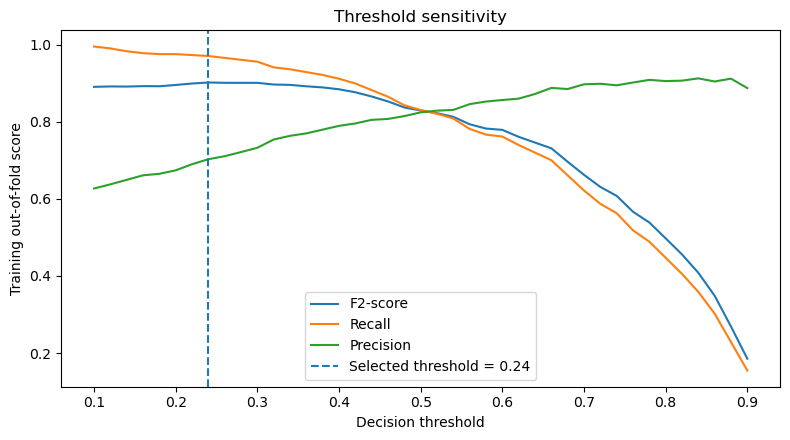

In [9]:
oof_probabilities = cross_val_predict(
    selected_estimator, X_train, y_train,
    cv=cv, method='predict_proba', n_jobs=-1
)[:, 1]
threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.901, 0.02), 2):
    pred = (oof_probabilities >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': float(threshold),
        'F2': fbeta_score(y_train, pred, beta=2, zero_division=0),
        'Precision': precision_score(y_train, pred, zero_division=0),
        'Recall': recall_score(y_train, pred, zero_division=0),
        'F1': f1_score(y_train, pred, zero_division=0),
    })
threshold_results = pd.DataFrame(threshold_rows)
# In a tie, prefer the higher threshold to avoid avoidable false-positive alerts.
threshold_best = threshold_results.sort_values(
    ['F2', 'Threshold'], ascending=[False, False]
).iloc[0]
selected_threshold = float(threshold_best['Threshold'])
print('Selected threshold (training OOF F2):', selected_threshold)
display(threshold_results.sort_values('F2', ascending=False).head(8).round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(threshold_results['Threshold'], threshold_results['F2'], label='F2-score')
ax.plot(threshold_results['Threshold'], threshold_results['Recall'], label='Recall')
ax.plot(threshold_results['Threshold'], threshold_results['Precision'], label='Precision')
ax.axvline(selected_threshold, linestyle='--', label=f'Selected threshold = {selected_threshold:.2f}')
ax.set(xlabel='Decision threshold', ylabel='Training out-of-fold score', title='Threshold sensitivity')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Final held-out evaluation

The selected estimator is fitted on the full training partition. The held-out test data are evaluated **once** using both the standard 0.50 threshold and the prespecified training-selected threshold. This comparison is descriptive; the test set does not influence model or threshold selection.

In [10]:
final_model = clone(selected_estimator).fit(X_train, y_train)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

def evaluate_threshold(y_true, probabilities, threshold):
    predicted = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        'Threshold': float(threshold),
        'Accuracy': accuracy_score(y_true, predicted),
        'Precision': precision_score(y_true, predicted, zero_division=0),
        'Recall': recall_score(y_true, predicted, zero_division=0),
        'F1': f1_score(y_true, predicted, zero_division=0),
        'F2': fbeta_score(y_true, predicted, beta=2, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'Average precision': average_precision_score(y_true, probabilities),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

test_results = pd.DataFrame([
    {'Configuration': 'Default threshold', **evaluate_threshold(y_test, test_probabilities, 0.50)},
    {'Configuration': 'Training-selected threshold', **evaluate_threshold(y_test, test_probabilities, selected_threshold)},
])
display(test_results.round(3))
print('Final model:', selected_name)
print(classification_report(y_test, (test_probabilities >= selected_threshold).astype(int), zero_division=0))

,Configuration,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average precision,TN,FP,FN,TP
0,Default threshold,0.50,0.853,0.850,0.892,0.871,0.883,0.924,0.938,66,16,11,91
1,Training-selected threshold,0.24,0.799,0.737,0.990,0.845,0.927,0.924,0.938,46,36,1,101


Final model: Random Forest
              precision    recall  f1-score   support

           0       0.98      0.56      0.71        82
           1       0.74      0.99      0.85       102

    accuracy                           0.80       184
   macro avg       0.86      0.78      0.78       184
weighted avg       0.84      0.80      0.79       184



## 10. Discrimination and classification errors

ROC-AUC measures ranking quality across thresholds; the confusion matrix reflects the errors at the training-selected operating point.

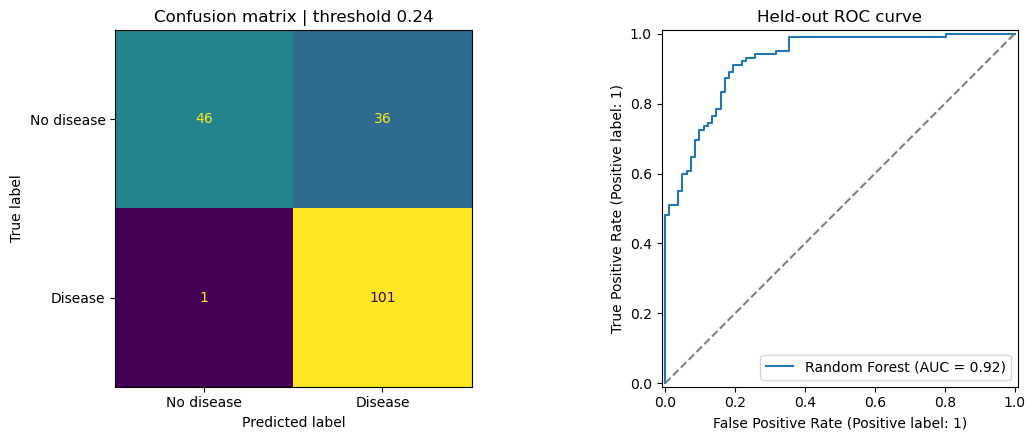

In [11]:
test_predictions = (test_probabilities >= selected_threshold).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1],
    display_labels=['No disease', 'Disease'], ax=axes[0], colorbar=False
)
axes[0].set_title(f'Confusion matrix | threshold {selected_threshold:.2f}')
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[1], name=selected_name)
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('Held-out ROC curve')
plt.tight_layout()
plt.show()

## 11. Permutation-based feature interpretation

Permutation importance measures changes in held-out ROC-AUC after shuffling one predictor at a time. It is a post-evaluation descriptive analysis and does not establish causality; correlated predictors may divide or obscure importance.

,Feature,ROC-AUC importance mean,ROC-AUC importance std
2,cp,0.0650,0.0158
4,chol,0.0344,0.0084
8,exang,0.0271,0.0075
9,oldpeak,0.0190,0.0067
1,sex,0.0133,0.0073
7,thalch,0.0090,0.0059
12,thal,0.0072,0.0059
5,fbs,0.0040,0.0012
11,ca,0.0037,0.0025
6,restecg,0.0020,0.0023


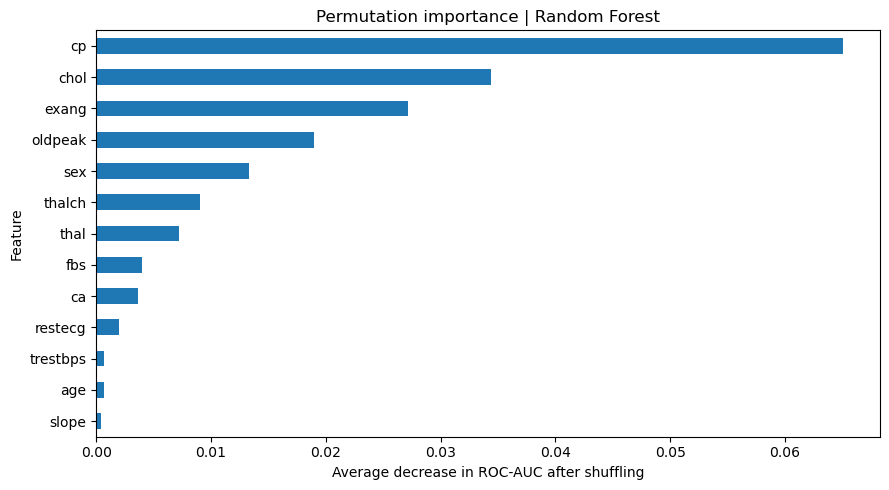

In [12]:
perm = permutation_importance(
    final_model, X_test, y_test, n_repeats=10,
    scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1,
)
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'ROC-AUC importance mean': perm.importances_mean,
    'ROC-AUC importance std': perm.importances_std,
}).sort_values('ROC-AUC importance mean', ascending=False)
display(importance_df.round(4))
importance_df.head(13).iloc[::-1].plot.barh(
    x='Feature', y='ROC-AUC importance mean', legend=False, figsize=(9, 5)
)
plt.title(f'Permutation importance | {selected_name}')
plt.xlabel('Average decrease in ROC-AUC after shuffling')
plt.tight_layout()
plt.show()

## 12. Reproducibility artifacts and result summary

Training-based selection tables, final metrics, model parameters, and the serialized classifier are saved under `outputs/`. The result summary is generated from measured values rather than embedded numeric claims.

In [13]:
cv_results.to_csv(OUTPUT_DIR / 'baseline_cv_results.csv', index=False)
tuning_results.to_csv(OUTPUT_DIR / 'hyperparameter_search_results.csv', index=False)
threshold_results.to_csv(OUTPUT_DIR / 'training_threshold_results.csv', index=False)
test_results.to_csv(OUTPUT_DIR / 'final_test_results.csv', index=False)
importance_df.to_csv(OUTPUT_DIR / 'permutation_importance.csv', index=False)
joblib.dump(final_model, OUTPUT_DIR / 'selected_model.joblib')

record = {
    'dataset_rows': len(X), 'features': X.shape[1],
    'negative_cases': int((y == 0).sum()), 'positive_cases': int(y.sum()),
    'training_rows': len(X_train), 'heldout_rows': len(X_test),
    'selected_model': selected_name,
    'selected_hyperparameters': selected_params,
    'selection_metric': 'stratified five-fold training CV ROC-AUC',
    'threshold_criterion': 'maximum F2 on training out-of-fold predictions',
    'threshold': selected_threshold,
    'test_results': test_results.to_dict(orient='records'),
}
(OUTPUT_DIR / 'experiment_metrics.json').write_text(
    json.dumps(record, indent=2, default=str), encoding='utf-8'
)
final_scores = test_results.iloc[1]
summary = (
    f'**Heart Disease Classification:** {len(X):,} records and {X.shape[1]} predictors; '
    'compared Logistic Regression and Random Forest with stratified five-fold '
    'cross-validation and randomized hyperparameter search. '
    f'**Selected model:** {selected_name} '
    f'(training CV ROC-AUC {searches[selected_name].best_score_:.3f}). '
    f'Training-based F2 optimization selected threshold {selected_threshold:.2f}. '
    f'**Held-out test:** accuracy {final_scores["Accuracy"]:.1%}, '
    f'ROC-AUC {final_scores["ROC-AUC"]:.3f}, '
    f'F1 {final_scores["F1"]:.3f}, recall {final_scores["Recall"]:.1%}; '
    f'{int(final_scores["FN"])} false negatives among {int(y_test.sum())} positive cases.'
)
(OUTPUT_DIR / 'github_result_line.md').write_text(summary + '\n', encoding='utf-8')
print(summary)

**Heart Disease Classification:** 920 records and 13 predictors; compared Logistic Regression and Random Forest with stratified five-fold cross-validation and randomized hyperparameter search. **Selected model:** Random Forest (training CV ROC-AUC 0.887). Training-based F2 optimization selected threshold 0.24. **Held-out test:** accuracy 79.9%, ROC-AUC 0.924, F1 0.845, recall 99.0%; 1 false negatives among 102 positive cases.


## 13. Discussion and limitations

### Experimental design

The binary endpoint, stratified partitions, and preprocessing pipelines provide a consistent basis for comparing linear and ensemble classifiers. Both baseline benchmarking and randomized hyperparameter search are restricted to training data. Model selection uses validation ROC-AUC, while threshold selection uses F2-score from out-of-fold training predictions. The selected classifier is subsequently assessed on the held-out partition.

### Interpretation

**Discrimination and classification are distinct outcomes.** ROC-AUC evaluates probability ranking, whereas precision, recall, F1, F2, and confusion-matrix counts depend on the selected classification threshold. Threshold optimization explicitly prioritizes sensitivity to positive cases but may increase false positives. The measured trade-off is reported in the final results table.

**Model complexity is assessed empirically.** Logistic Regression provides a regularized linear reference; Random Forest captures nonlinear relationships and interactions. Their relative merit is determined using validation scores rather than assumptions about model flexibility.

**Feature importance represents predictive association.** Permutation-based effects summarize the fitted model's sensitivity to individual predictors, not the causal influence of those variables on heart disease.

### Limitations

The dataset is relatively small and includes missing clinical measurements. Hyperparameter and threshold selection reuse the same training partition, so the reported training-validation maxima may be optimistic. Prior exploratory work also examined a hold-out split from this dataset; consequently, the final hold-out should be interpreted as a reproducible benchmark comparison rather than a wholly prospective independent validation. External validation, preferably on a newly collected cohort, would be required to establish generalization. The models are not clinically validated diagnostic systems.

### Conclusion

This experiment combines pipeline-based preprocessing, cross-validated model comparison, training-only hyperparameter search, out-of-fold threshold optimization, and final hold-out assessment. The generated metrics provide a transparent record of discrimination, classification performance, and false-negative trade-offs for the selected configuration.